In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns


In [2]:
traffic_flow = pd.read_csv("./data/traffic.csv")
county =  pd.read_csv("./data/location.csv")
df = pd.merge(traffic_flow,county,left_on = "id",right_on = "loc_id",how = "left").drop(columns=["loc_id","Unnamed: 0"])

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16125588 entries, 0 to 16125587
Data columns (total 8 columns):
 #   Column             Dtype  
---  ------             -----  
 0   timestamp          str    
 1   id                 int64  
 2   flow               int64  
 3   latitude           float64
 4   longitude          float64
 5   county_id          int64  
 6   city_id            float64
 7   freeway_direction  str    
dtypes: float64(3), int64(3), str(2)
memory usage: 984.2 MB


In [4]:
df.isna().sum()

timestamp                  0
id                         0
flow                       0
latitude                   0
longitude                  0
county_id                  0
city_id              3794256
freeway_direction          0
dtype: int64

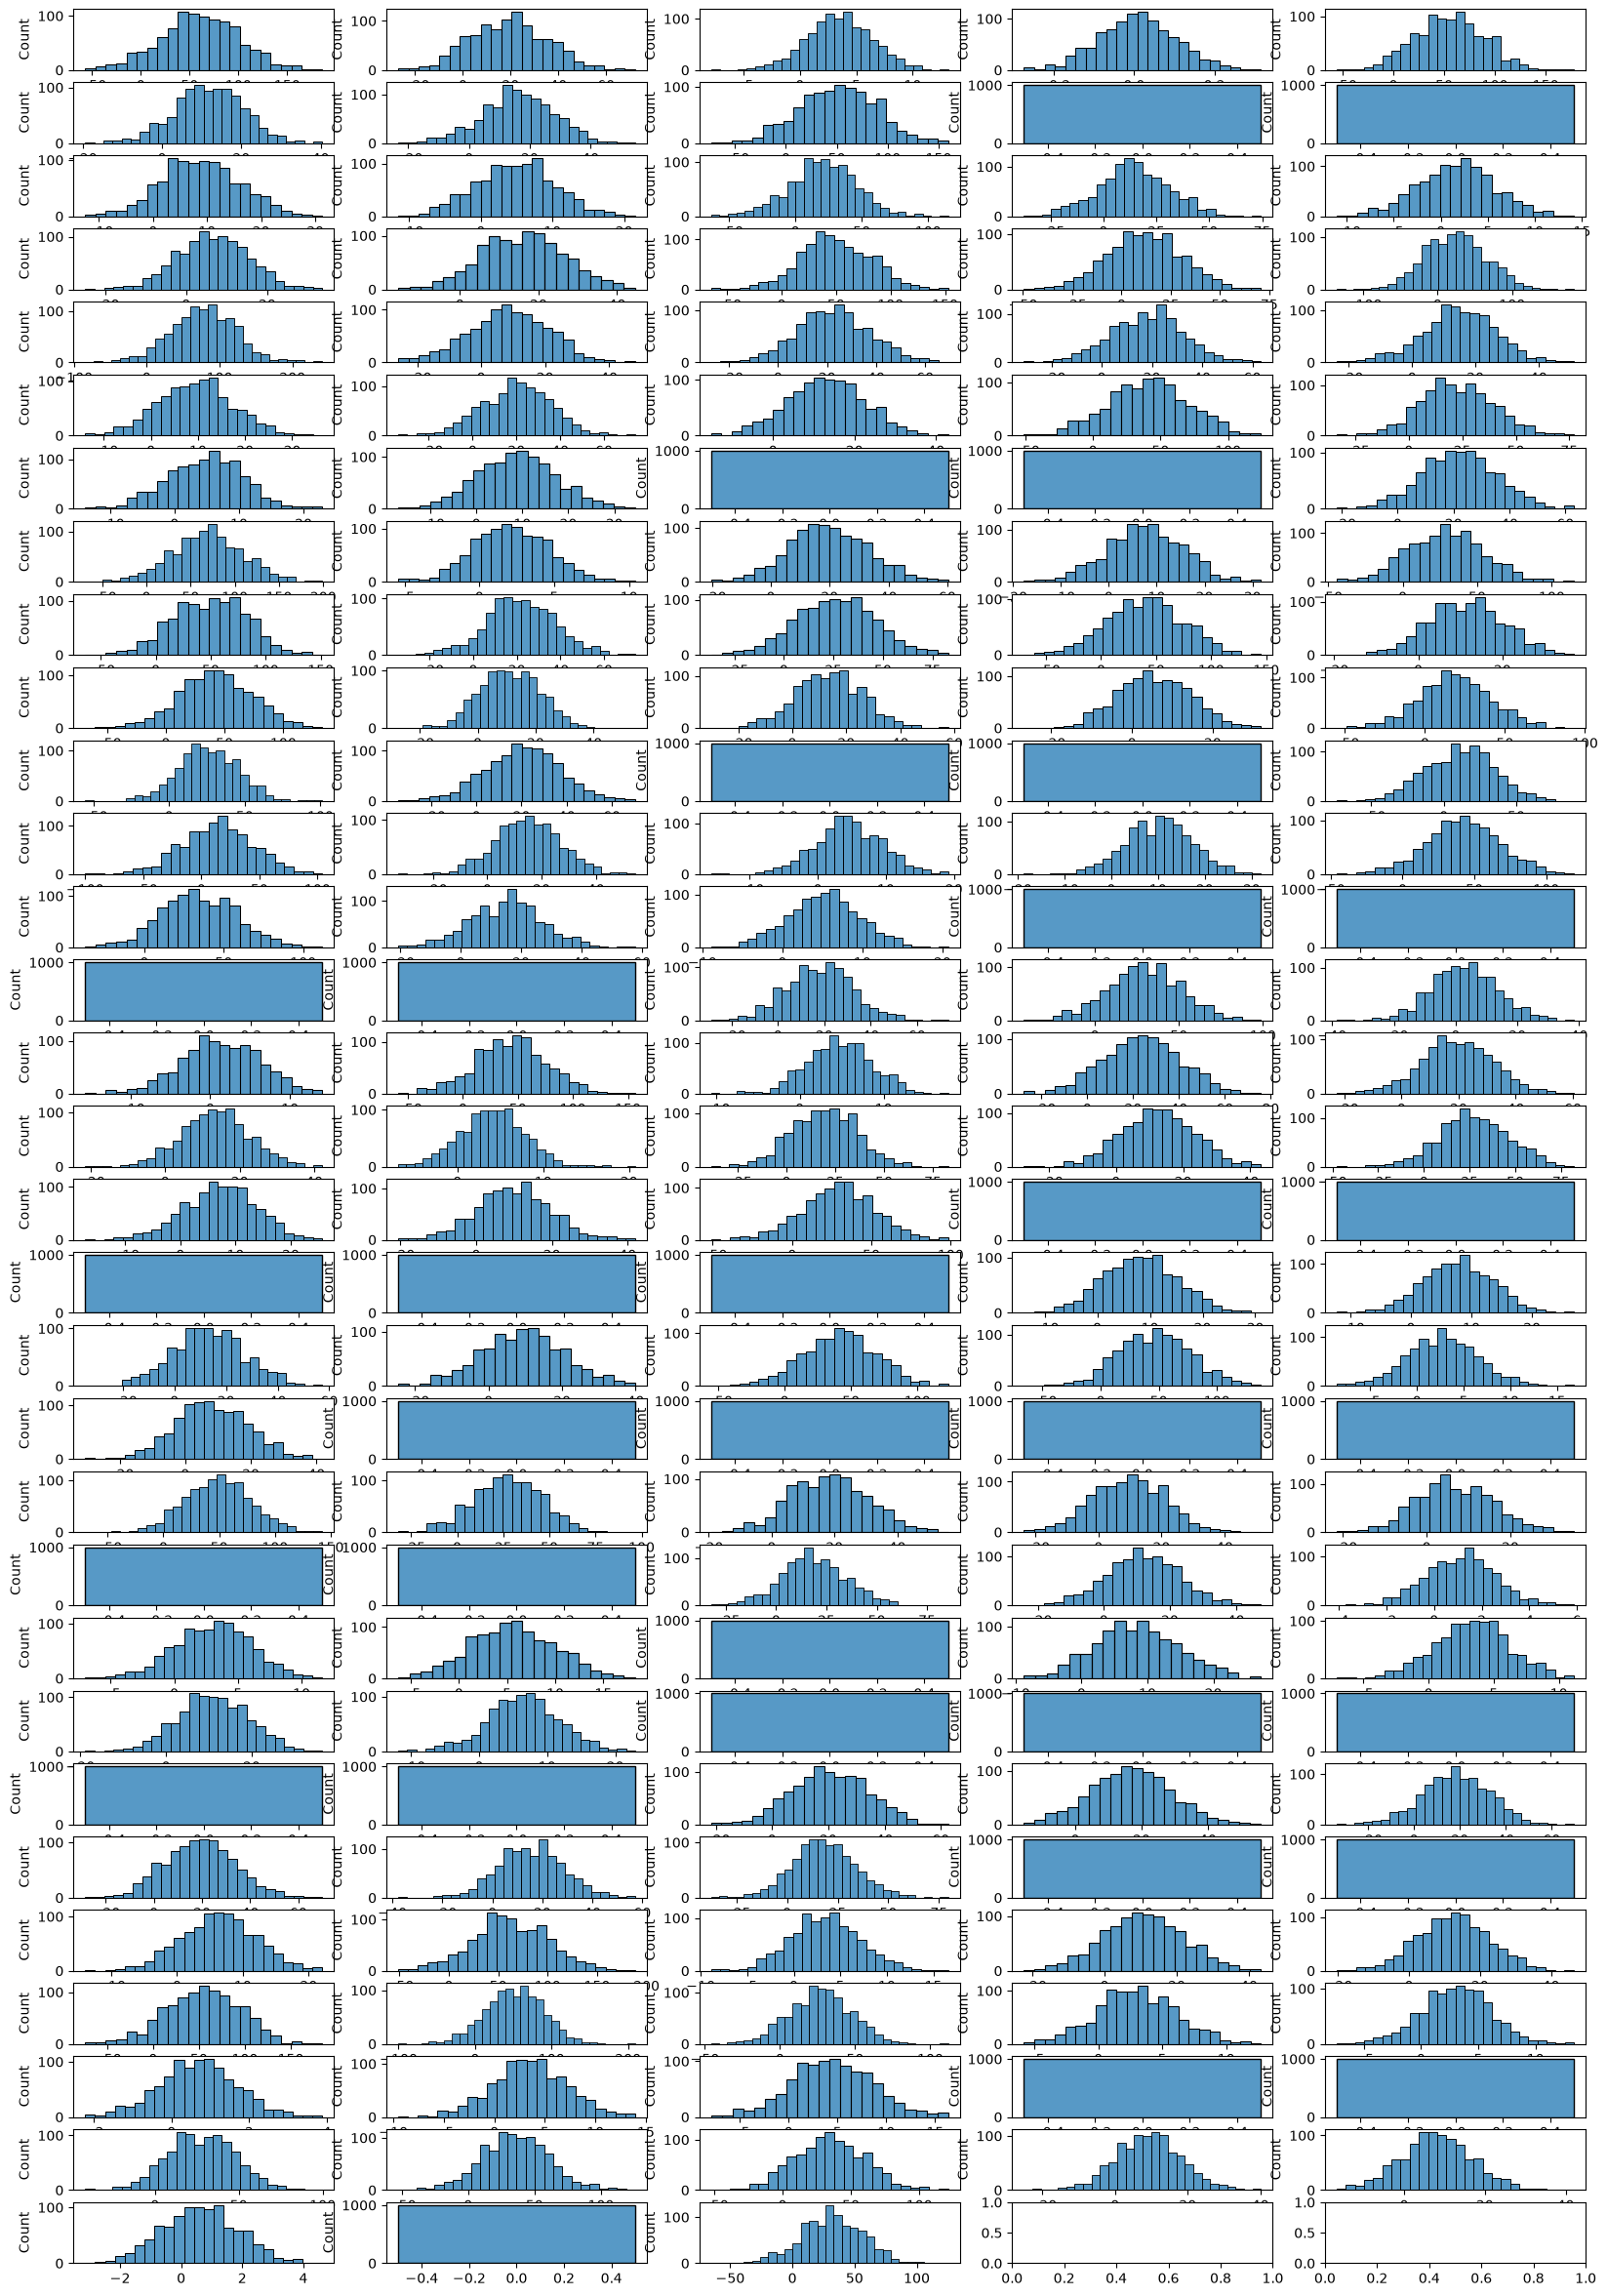

In [16]:
df2 =  df.drop(columns= ["timestamp"])
ids = df2["id"].unique()
fig , axes =  plt.subplots(31,5,figsize=(20,30))
axes = axes.ravel()
id_mean_std = {}
for i, id in enumerate(ids):
    d = df2[df2["id"]==id]["flow"]
    mean,std = d.mean() , d.std()
    id_mean_std[id] = [mean,std]
    samples = np.random.normal(loc =  mean,scale= std,size = 1000)
    sns.histplot(samples,ax = axes[i])

In [ ]:
ids =  [key  for key in id_mean_std if id_mean_std[key][0] > 0 ]
df3 = df [df["id"].isin(ids)]
data = pd.pivot(df3,index = "timestamp",columns ="id",values = "flow").reset_index().sort_values(by="timestamp")
data.head()

id,timestamp,200,201,300,301,500,501,700,701,1100,...,22103,22200,22201,24000,24001,24200,24201,24700,24701,24901
0,01/01/2012 00:00:00,0,0,1,0,7,3,5,12,8,...,0,1,3,7,2,4,1,4,1,6
1,01/01/2012 00:05:00,0,0,2,0,8,0,0,12,8,...,0,0,0,7,8,4,0,4,0,5
2,01/01/2012 00:10:00,0,0,0,0,9,1,3,14,6,...,0,0,1,6,5,5,0,8,0,6
3,01/01/2012 00:15:00,0,0,1,0,20,4,11,15,8,...,0,2,2,6,9,9,2,3,3,9
4,01/01/2012 00:20:00,0,0,4,0,16,3,8,24,5,...,0,1,0,4,12,10,2,10,1,18


In [33]:
data.describe()

id,200,201,300,301,500,501,700,701,1100,1101,...,22103,22200,22201,24000,24001,24200,24201,24700,24701,24901
count,105396.000000,105396.000000,105396.000000,105396.000000,105396.000000,105396.000000,105396.000000,105396.000000,105396.000000,105396.000000,...,105396.000000,105396.000000,105396.000000,105396.000000,105396.00000,105396.000000,105396.000000,105396.000000,105396.000000,105396.000000
mean,59.708034,19.795533,3.423707,0.008359,54.148383,11.716536,15.766822,51.750085,8.700131,4.952313,...,0.657748,3.635432,4.575221,27.310239,34.85045,34.360659,9.165642,8.590051,0.605004,32.492571
std,41.211429,16.290059,2.870455,0.096508,35.077416,8.606049,11.777945,38.596874,7.440391,5.670428,...,1.000518,3.609834,4.230788,20.318964,25.91779,26.500242,9.108034,8.841108,1.241581,24.472373
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,18.000000,6.000000,1.000000,0.000000,20.000000,5.000000,5.000000,14.000000,3.000000,1.000000,...,0.000000,0.000000,1.000000,7.000000,10.00000,9.000000,2.000000,0.000000,0.000000,7.000000
50%,64.000000,18.000000,3.000000,0.000000,56.000000,11.000000,15.000000,54.000000,7.000000,3.000000,...,0.000000,3.000000,4.000000,27.000000,34.00000,33.000000,7.000000,6.000000,0.000000,34.000000
75%,93.000000,28.000000,5.000000,0.000000,83.000000,17.000000,23.000000,78.000000,13.000000,7.000000,...,1.000000,6.000000,7.000000,42.000000,54.00000,51.000000,13.000000,16.000000,1.000000,53.000000
max,198.000000,111.000000,27.000000,4.000000,160.000000,56.000000,77.000000,207.000000,73.000000,73.000000,...,8.000000,26.000000,24.000000,106.000000,147.00000,146.000000,67.000000,50.000000,18.000000,132.000000


Distribution of By Days 

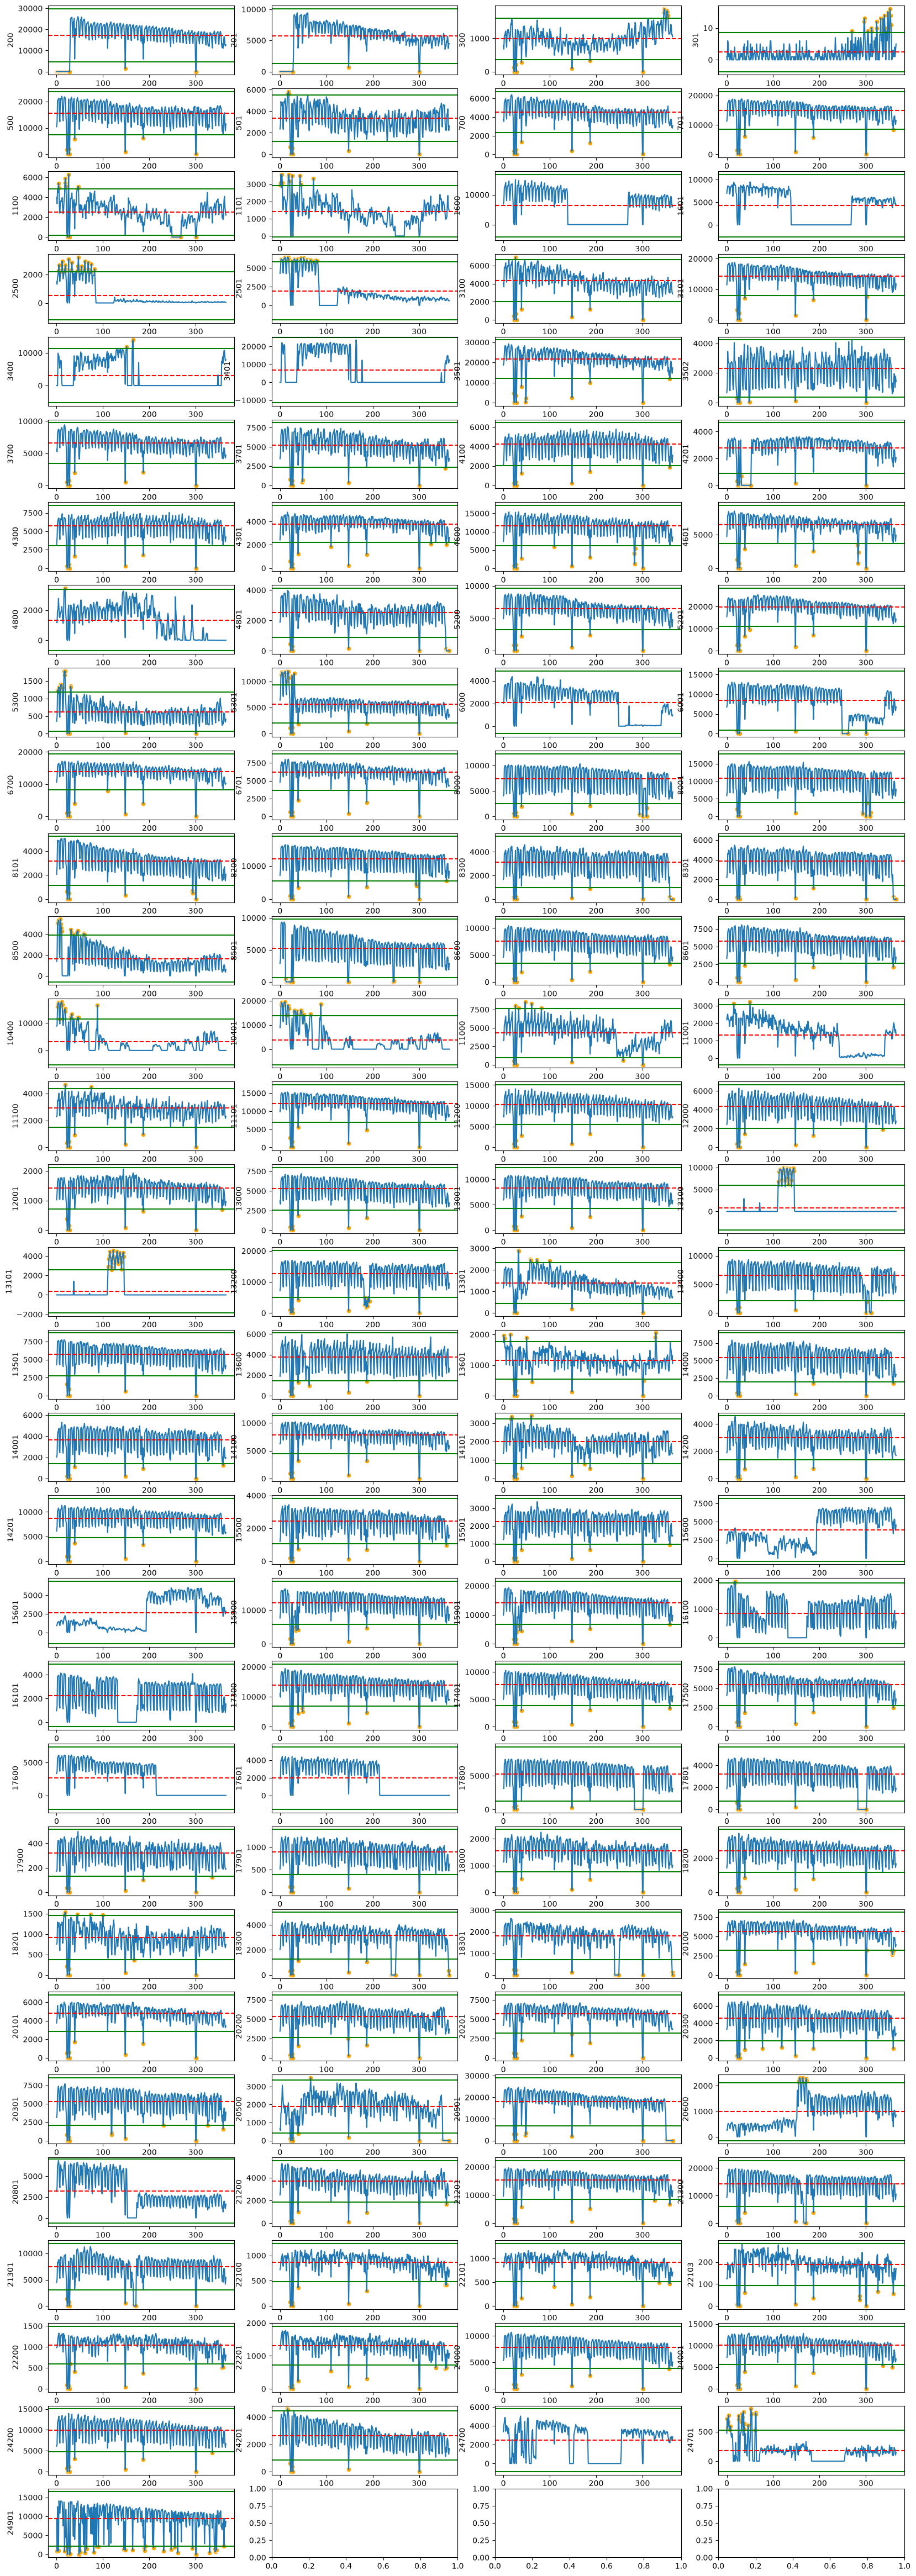

In [60]:
data["date"] =  data["timestamp"].map(lambda x:x[:10])
g = data.drop(columns=["timestamp"]).groupby("date").sum()
x_axis = np.arange(366)
fig,axes =  plt.subplots(31,4,figsize= (20,60))
axes = axes.ravel()

for i,column in enumerate(g.columns):
    mean,std = g[column].mean(),g[column].std()
    a = sns.lineplot(x = x_axis,y = g[column],ax = axes[i])
    a.axhline(y = mean,color = "red",linestyle ="--")
    a.axhline(y = mean-2*std,color = "green")
    a.axhline(y =  mean+2*std,color = "green")
    values =  g[column].values
    flag = (values>mean+2*std) | (values<mean-2*std)
    sns.scatterplot(x =  x_axis[flag],y =  values[flag],ax = axes[i],color =  "orange")

So from above graphs, we can infer that some of the routes are active only some part of the year. We can Impute the values or completely igonre them. 
Currently Lets focus on the routes that are consistent across the year.
All the Stations have same distribution in some days of the year. Those could potentially be Holidays or Special Events.

Let me omit the Stations - [24700,17600,17601,13100,13101,2500,2501,3400,3401,1600,1601]

There could be posssibilities of duplicate Stations(Same flow of traffic).
To identify this, will conduct chi_square test.

In [ ]:
from scipy import stats
data2 = data.drop(columns = [24700,17600,17601,13100,13101,2500,2501,3400,3401,1600,1601,"timestamp","date"])
n = data2.shape[1]
def chi_square(a,b):
    chi,p_value = stats.chisquare(a,b)
    return p_value<=0.05
chi2_matrix = [[False]*n for _ in range(n)]
cols =  data2.columns
for i in range(n):
    s1 = data2[cols[i]].sum()
    for j in range(i,n):
        s2 =  data2[cols[j]].sum()
        chi2_matrix[i][j] = chi_square(data2[cols[i]]+1,(data2[cols[j]]/s2)*s1+1)


<Axes: >

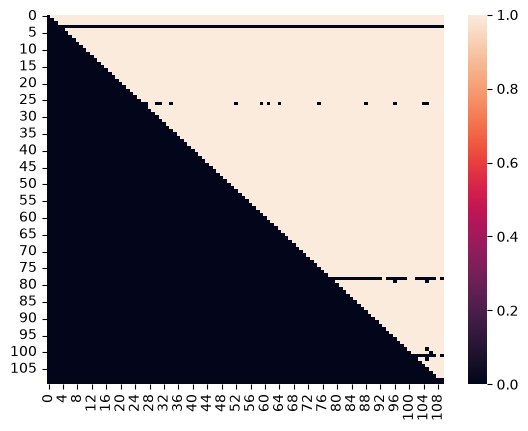

In [72]:
sns.heatmap(chi2_matrix)

In [78]:
rows = []
m = [True]*110
for i in range(110):
    for j in range(i+1,110):
        if not chi2_matrix[i][j] and m[j]:
            rows.append(cols[i])
            m[i] = False
            break
rows

[301, 5300, 17900, 17901, 22100, 22101, 22103, 22200, 24701]

Clearly the columns [301, 5300, 17900, 17901, 22100, 22101, 22103, 22200, 24701] are having exact same distribution with other columns. 
So Total Columns can be ignores = [301, 5300, 17900, 17901, 22100, 22101, 22103, 22200, 24701,24700,17600,17601,13100,13101,2500,2501,3400,3401,1600,1601]

Lets take the sample of each station and calulated the ACF and PACF to know how lags affect the current value.

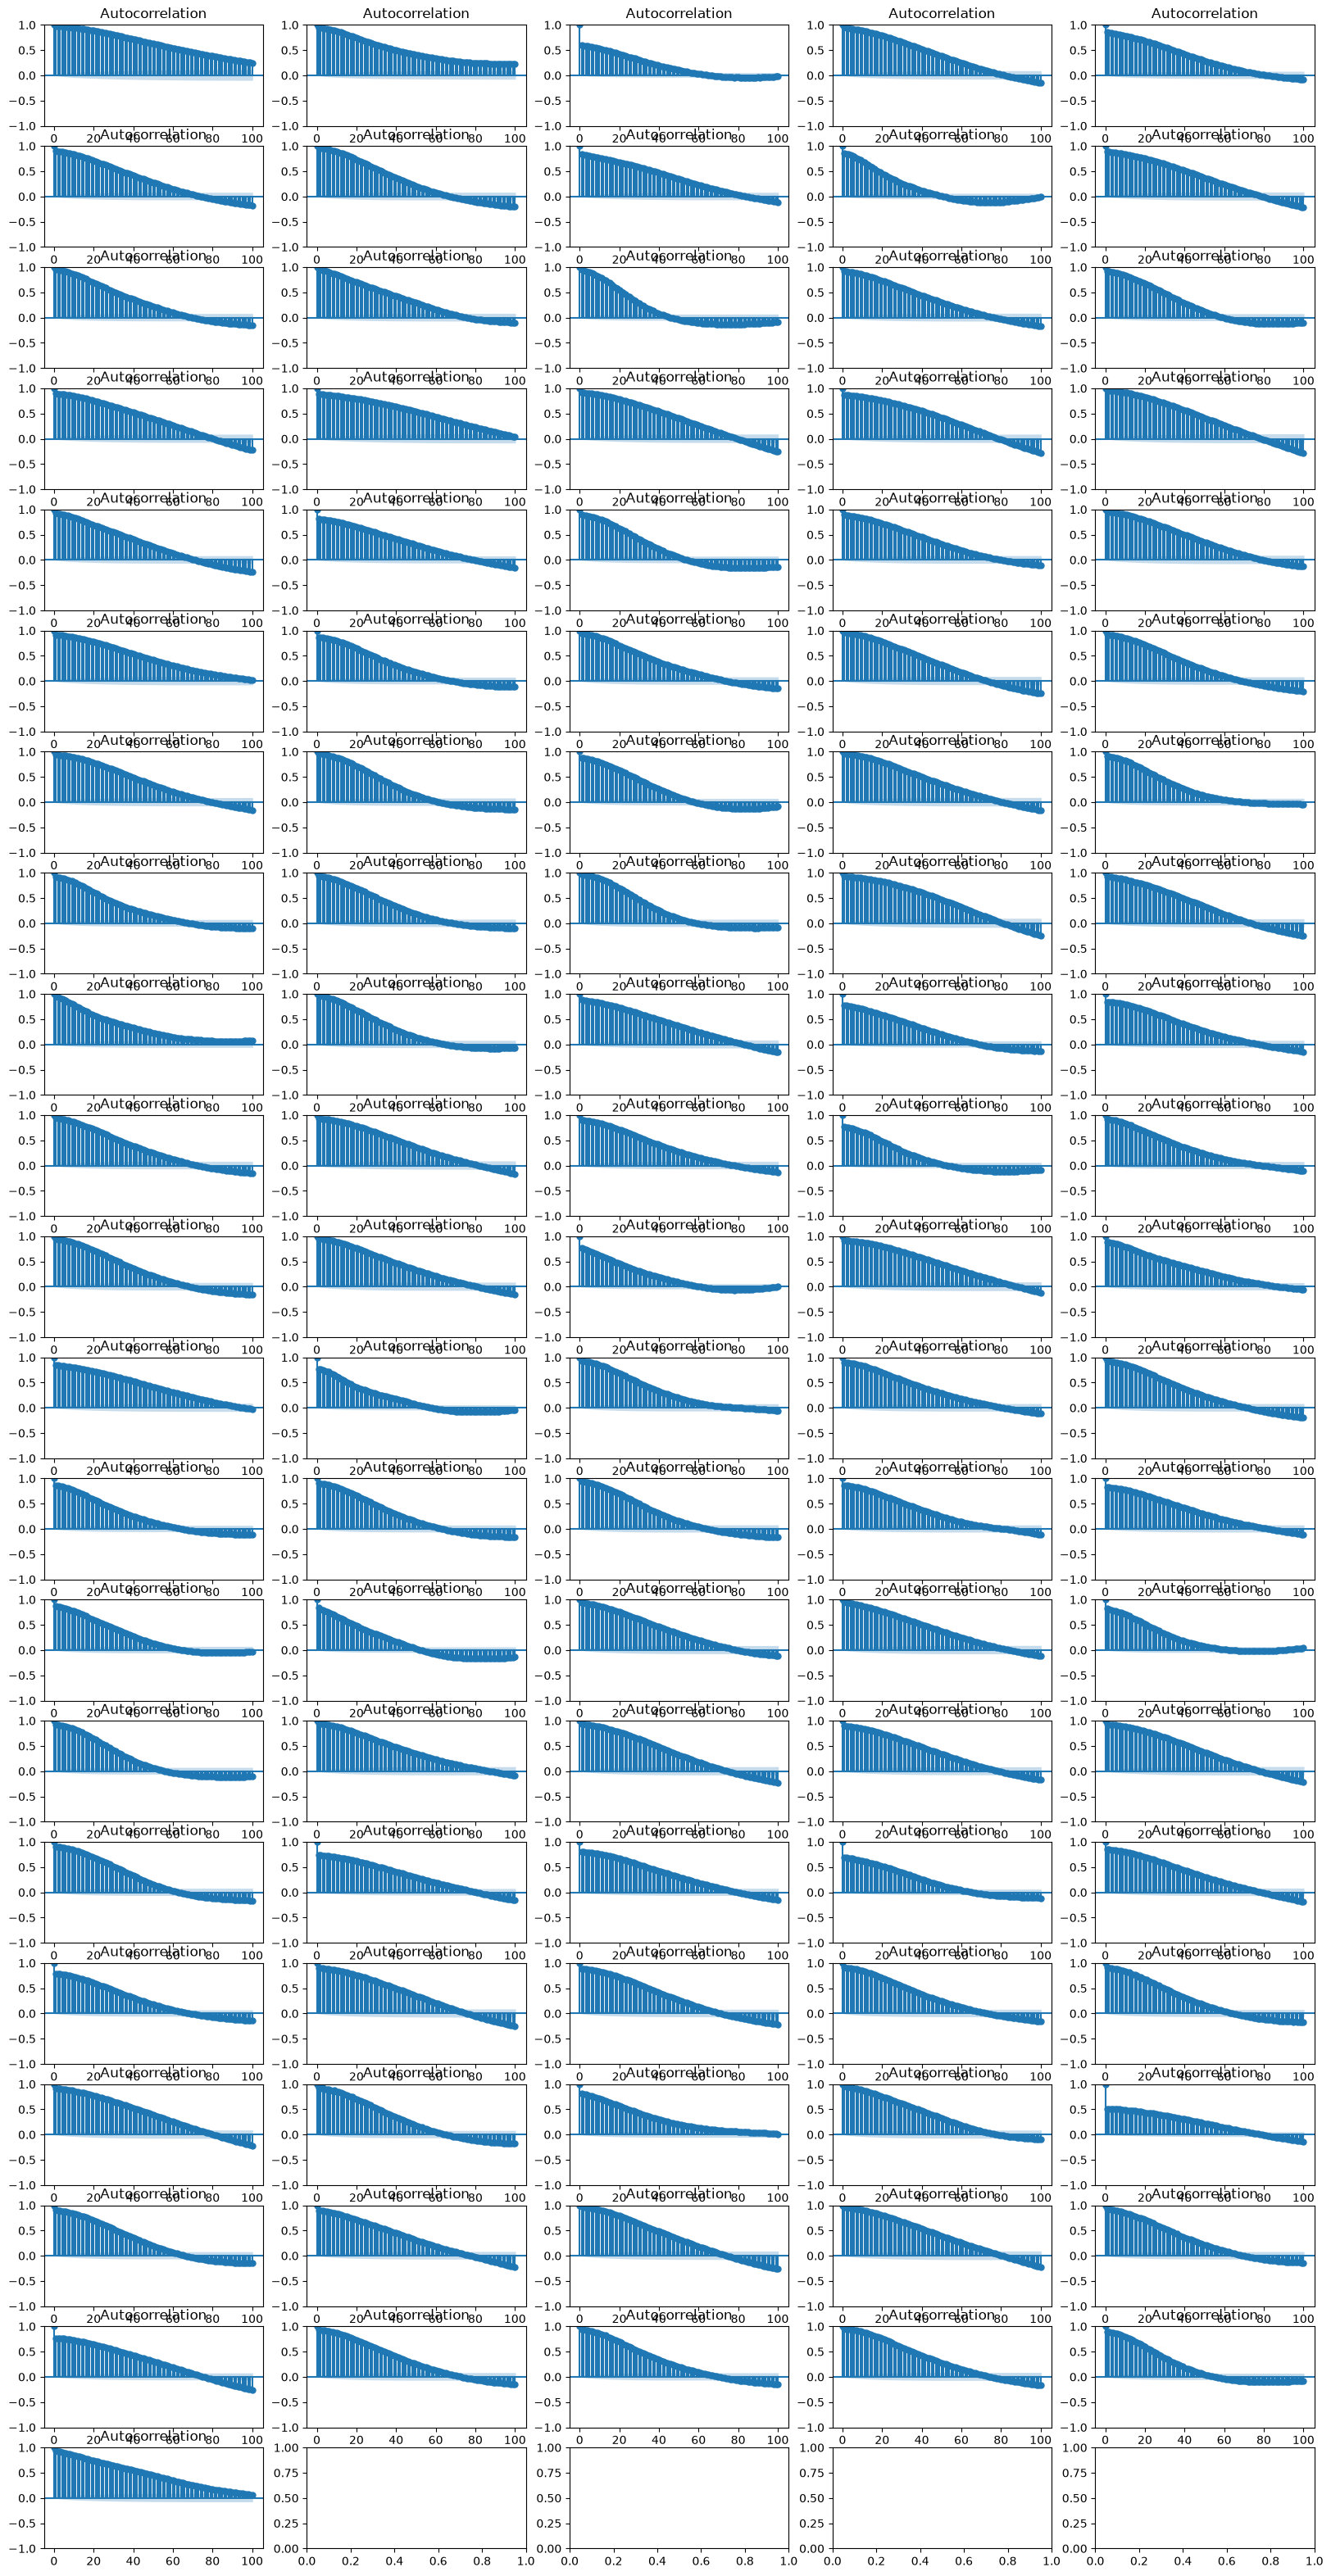

In [89]:
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
sample =  data.drop(columns = [301, 5300, 17900, 17901, 22100, 22101, 22103, 22200, 24701,24700,17600,17601,13100,13101,2500,2501,3400,3401,1600,1601,"date","timestamp"]).iloc[:30000,:]
fig,axes =  plt.subplots(21,5,figsize=(20,40))
axes = axes.ravel()
for idx,col in enumerate(sample.columns):
    plot_acf(sample[col],lags =  100,ax = axes[idx])


Almost all stations following the same pattern. The nearby lags are positively correlated and as the lag increases correations starts decaying and also goes to negative correlation.
Meaning that traffic swings between high and low periodically.
Lets check how the stations have relationship with nearby stations.

In [130]:
location = county.drop(columns = ["Unnamed: 0","city_id","freeway_direction","county_id"])
location.index = location["loc_id"]
location = location.drop(columns = ["loc_id"])
distance = dict()
def calcDistance(columns):
    for a in columns:
        distance[a] = []
        for b in columns:
            distance[a].append([np.linalg.norm(location.loc[a,:].values-location.loc[b,:].values),b])
    return distance
    
distance = calcDistance(sample.columns)
for key in distance:
    distance[key].sort(key = lambda x:x[0])

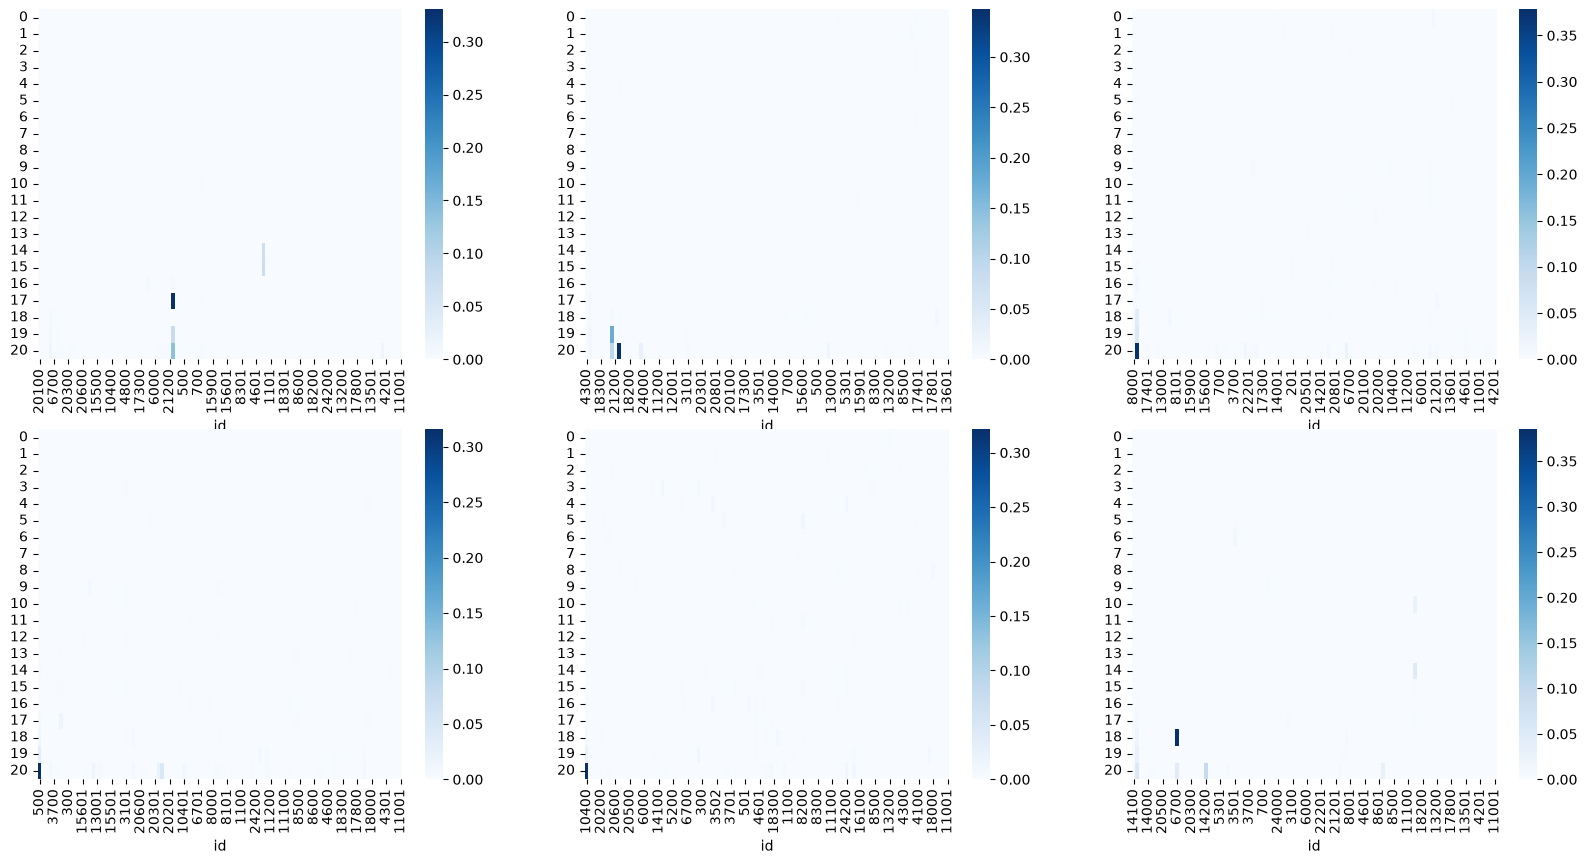

In [146]:
def convert_to_timeseries(data,target,step=12,gap = 9):
    m,n = data.shape
    if m<=step:
        print("Data length is not sufficient")
        return 
    x = []
    for i in range(step+gap,m):
        x.append(list(data.iloc[i-step-gap:i,:].values.ravel()))
    y = data.loc[step+gap:,target]
    return x,y

def calcImportance(x,y):
    from xgboost import XGBRegressor
    n = sample.shape[1]
    model = XGBRegressor()
    model.fit(x,y)
    importance =  pd.DataFrame(model.feature_importances_.reshape(-1,n))
    importance.columns =  sample.columns
    return importance
fig,axes  =  plt.subplots(2,3,figsize=(20,10))
axes = axes.ravel()
for i,key in enumerate(np.random.choice(sample.columns,6)):
    cols = [col for _,col in distance[key]]
    x,y = convert_to_timeseries(sample,key)
    importance = calcImportance(x,y)[cols]
    sns.heatmap(importance,cmap = "Blues",ax= axes[i])


Average Traffic Flow per Station

In [155]:
import folium
def drawMap(points):
    my_map  = folium.Map(location = [points["latitude"].mean(),points["longitude"].mean()] )
    indices =  points.index
    for ind in indices:
        x,y =  points.loc[ind,:] 
        folium.Marker(location = [x,y],popup = ind).add_to(my_map)
    my_map.save("map.html")
drawMap(location.loc[[4300,18300,18200,21200]])

<Axes: xlabel='county_id', ylabel='flow'>

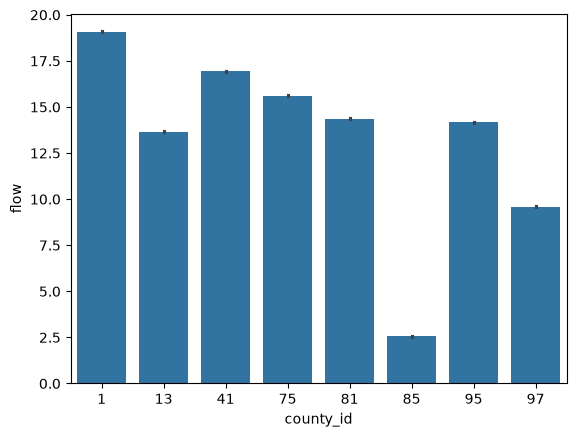

In [45]:
sns.barplot(x = df["county_id"], y = df["flow"] , estimator = "mean")

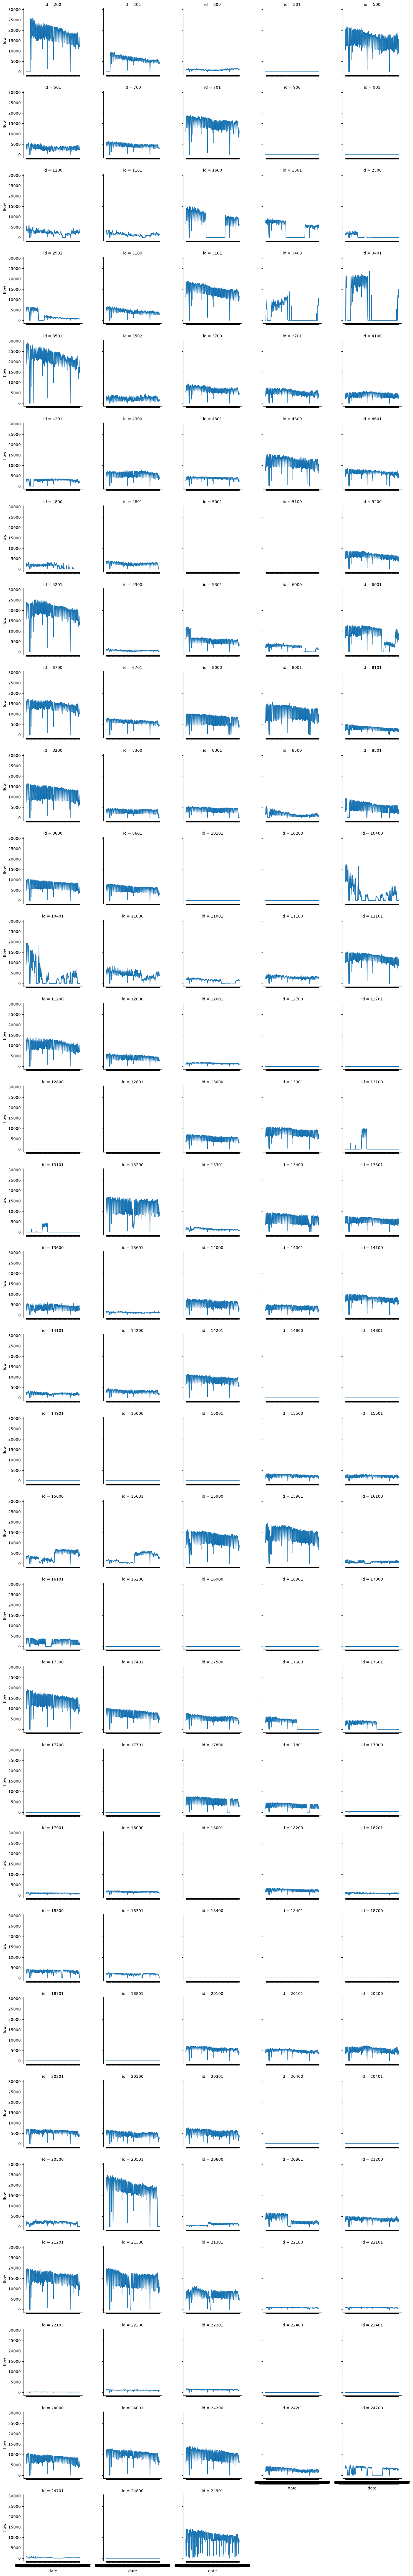

In [14]:
data =  df.groupby(["date","id"])["flow"].sum().reset_index()
g = sns.FacetGrid(data,col = "id",col_wrap = 5)
g.map(sns.lineplot,"date","flow")

<Axes: xlabel='date', ylabel='id'>

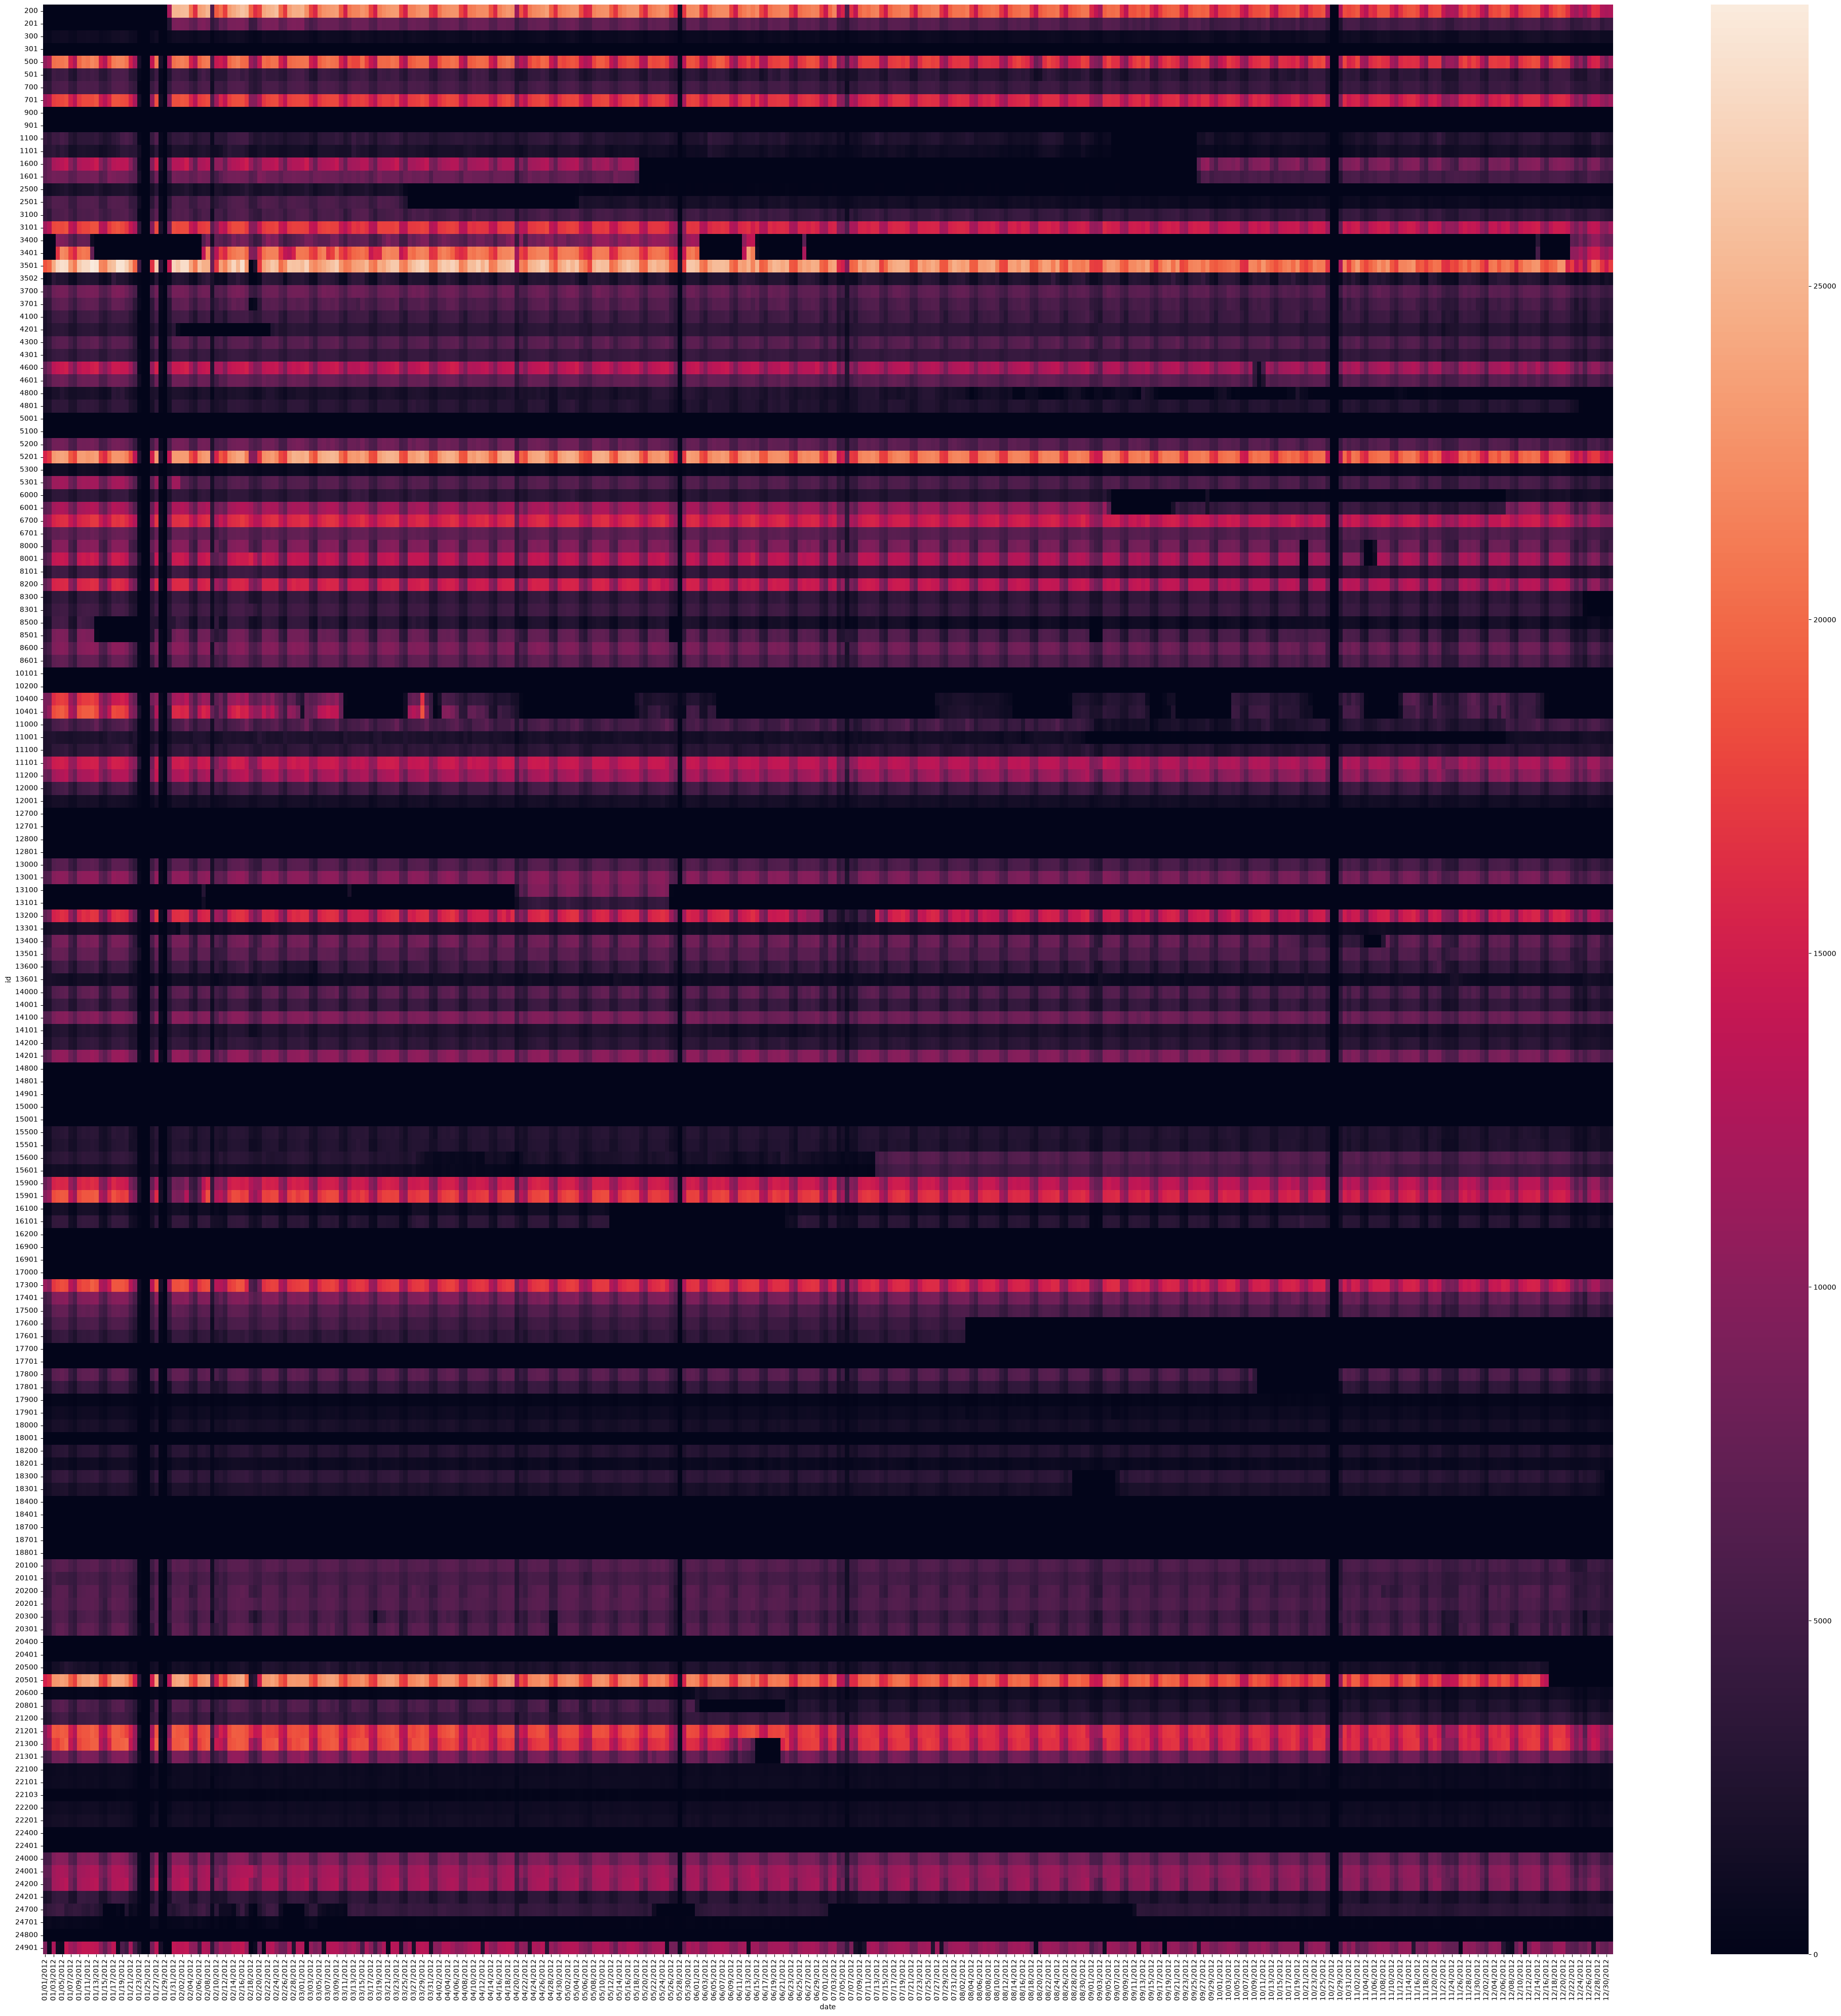

In [18]:
fig,ax = plt.subplots(figsize=(50,50))
sns.heatmap(data.pivot(index = "id",columns = "date",values = "flow"),ax = ax)

In [130]:
cords = county[county["loc_id"]==8601][["longitude","latitude"]].values
def calc_distance(row):
    return np.linalg.norm(cords-row[["longitude","latitude"]].values)
dist =  county.copy()
dist["dist"] = county.apply(lambda x:calc_distance(x),axis = 1)
nearest = dist.sort_values(by = ["dist"])["loc_id"].values[:40]

In [156]:

import os
os.cpu_count()
        

12

In [141]:
truncated =  data.loc[:,nearest]
s= data.loc[:,nearest].sum()
s = s[s==0]
truncated = truncated.drop(columns = s.index)
x,y = convert_to_timeseries(truncated,12)
truncated.head()

id,8601,8600,16101,16100,8500,8501,8101,8200,17401,17500,...,5300,5301,22100,22101,22103,18000,17900,17901,17800,17801
timestamp,,,,,,,,,,,,,,,,,,,,,
01/01/2012 00:00:00,4,3,1,0,3,4,4,6,3,1,...,0,5,0,0,0,0,0,1,2,0
01/01/2012 00:05:00,1,4,2,2,1,2,2,1,4,6,...,1,6,0,0,0,1,0,1,3,1
01/01/2012 00:10:00,3,7,2,0,2,0,2,11,3,8,...,0,9,1,1,0,0,0,1,2,2
01/01/2012 00:15:00,6,10,0,3,1,2,0,16,8,11,...,0,5,2,0,0,0,0,0,4,0
01/01/2012 00:20:00,4,17,0,1,9,4,6,16,6,18,...,0,15,0,2,0,1,2,0,2,2


In [142]:
X = pd.DataFrame(x)
Y = pd.Series(y)
X.head()

,0,1,2,3,4,5,6,7,8,9,...,374,375,376,377,378,379,380,381,382,383
0,4,3,1,0,3,4,4,6,3,1,...,2,19,0,2,0,6,0,0,12,8
1,1,4,2,2,1,2,2,1,4,6,...,0,35,2,0,0,4,0,1,19,5
2,3,7,2,0,2,0,2,11,3,8,...,0,36,1,2,0,3,0,2,14,1
3,6,10,0,3,1,2,0,16,8,11,...,1,18,0,1,1,3,0,1,12,7
4,4,17,0,1,9,4,6,16,6,18,...,1,26,0,1,0,10,0,1,9,3


In [144]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size = 0.3)

In [148]:
from xgboost import XGBRegressor
model = XGBRegressor()
model.fit(x_train,y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [162]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,mean_absolute_percentage_error
predicted = model.predict(x_test)
print(mean_absolute_error(y_test,predicted),mean_squared_error(y_test,predicted),mean_absolute_percentage_error(y_test+1,predicted+1))

3.5351169109344482 25.575475692749023 0.2909370958805084


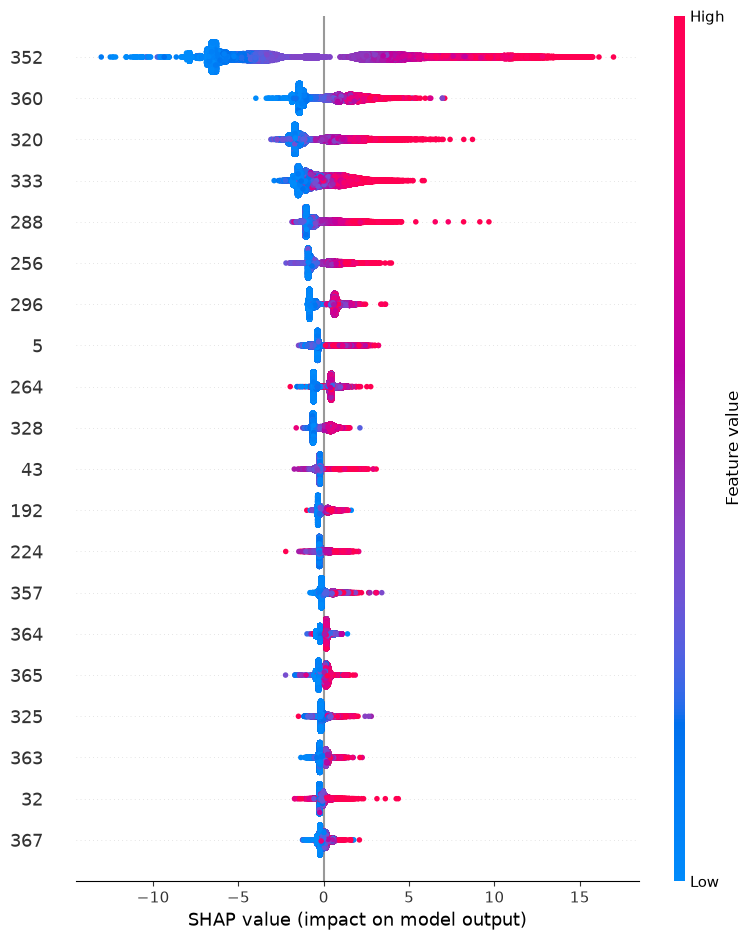

In [165]:
import shap
exp = shap.TreeExplainer(model)
shap_values = exp.shap_values(x_train)
shap.summary_plot(shap_values,x_train)

In [166]:
nearest

array([ 8601,  8600, 16101, 16100,  8500,  8501, 18701, 18700, 14901,
       15000, 15001,  8101,  8200, 17401, 17500,  8000,  8001, 15900,
       15901,  8300,  8301, 22400, 22401, 22200, 22201, 13101, 13100,
       17600, 17601,  5300,  5301, 22100, 22101, 22103, 18001, 18000,
       17900, 17901, 17800, 17801])

In [171]:
383-31

352